# 16_4 · Calibración G/F con inhibición fijada según Zenteno

Se compara el modelo G/F actual del 16_3, con los parámetros guardados del 16_2, frente a una recalibración con seis parámetros libres y las dos constantes de inhibición fijadas. Se utiliza la regla de crecimiento mientras quede glucosa o fructosa en ambos casos.

Se fija \(K_{IE0}=40\,\mathrm{g\,E/L}\) a 20 °C. Para convertir la indicación \(S/4\) de la tabla 2 de Zenteno (2010) en un parámetro fijo, se adopta \(K_{IG0}=(G_0+F_0)/4\) en cada lote. **La elección de usar el azúcar inicial es una interpretación explícita para este ensayo.** Ese valor queda constante dentro del lote y conserva la misma dependencia térmica del modelo actual.

Se mantienen los datos, el tratamiento de nitrógeno, las condiciones iniciales, las temperaturas y los pulsos del 16_3. El ajuste usa LAB004–009. LAB016–024 se usan para evaluar las concentraciones. Se conservan la solubilidad variable y los coeficientes de gas heredados del 16_2; LAB019–021 participaron en su calibración previa. Los resultados se muestran en este notebook.

Referencia: Zenteno y colaboradores, *Modeling temperature gradients in wine fermentation tanks*, tabla 2, https://doi.org/10.1016/j.jfoodeng.2010.01.033.

In [1]:
from pathlib import Path
from types import FunctionType
import json

import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/wine_fermentation").is_dir())
source, = (ROOT / "notebooks").glob("16_2_*.source.ipynb")
calibration = nbformat.read(source, 4)
saved = nbformat.read(source.with_name(source.name.replace(".source.", ".executed.")), 4)
assert [cell.source for cell in calibration.cells] == [cell.source for cell in saved.cells]
[output] = [o.text.split("PARÁMETROS QUÍMICOS COMPLETOS", 1)[1].lstrip()
            for o in saved.cells[5].outputs
            if o.output_type == "stream" and "PARÁMETROS QUÍMICOS COMPLETOS" in o.text]
theta, _ = json.JSONDecoder().raw_decode(output)

def reference(index, start=None, stop=None):
    code = calibration.cells[index].source
    if start is not None:
        assert code.count(start) == 1
        code = code[code.index(start):]
    if stop is not None:
        assert code.count(stop) == 1
        code = code[:code.index(stop)]
    return code

setup = {"__name__": "__main__", "display": lambda *_: None}
for code in (reference(1, stop="start=kin.normalize_parameters"),
             reference(3),
             reference(12, stop="cores,caches,activation=build_curves(theta)"),
             reference(12, start="KLA, GAIN =", stop="curves={lab:gas(lab,KLA,GAIN)"),
             reference(13)):
    exec(compile(code, source.name, "exec"), setup)
kin = setup["kin"]
assert set(theta) == set(kin.PARAMETERS)
display(pd.Series(theta, name="Parámetros guardados del 16_2"))
print("Capa de CO₂ del 16_2", setup["HOLDOUT_GAS_PARAMS"])

,LAB,original_g_L,viables_millones_mL,corregido_g_L
0,LAB004,0.3939,10.75,0.3225
1,LAB005,0.4932,11.25,0.3375


Pares de réplicas: 23 sigma réplica: 0.1189341469231937 sigmaX de referencia del 16: 0.5


,LAB,agotamiento_h,corte_YAN_h,N0_mg,pulsos,X,N,G,F,E
0,LAB004,91.0,103.0,230.76,"((68.5, 0.08),)",10,8,12,12,4
1,LAB005,91.0,103.0,227.30,"((68.5, 0.08),)",10,8,12,12,4
2,LAB006,122.0,134.0,229.12,"((100.0, 0.08),)",12,9,14,14,4
3,LAB007,88.0,100.0,239.04,"((65.5, 0.08),)",11,8,12,12,5
4,LAB008,88.0,100.0,239.22,"((65.5, 0.08),)",11,8,12,12,5
5,LAB009,64.0,76.0,237.40,"((41.84615384615385, 0.08),)",10,6,11,11,4


,LAB,t_h,original_mg,usado_mg,estado
0,LAB004,0.0,230.76,230.76,Inicial
1,LAB004,19.0,182.72,182.72,Usado
2,LAB004,26.0,157.42,157.42,Usado
3,LAB004,43.0,60.16,60.16,Usado
4,LAB004,50.0,19.00,0.00,Transformado
...,...,...,...,...,...
74,LAB009,88.0,17.00,NaN,Excluido
75,LAB009,96.0,19.00,NaN,Excluido
76,LAB009,120.0,5.00,NaN,Excluido
77,LAB009,144.0,25.00,NaN,Excluido


Observaciones en el objetivo {'X': 64, 'N': 47, 'G': 73, 'F': 73, 'E': 26}


,LAB,X,N,G,F,E,pulsos,corte_h
0,LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08648648648648648),)",166.000000
1,LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08888888888888889),)",172.333333
2,LAB021,0.270000,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08648648648648648),)",166.000000
3,LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)",151.100000
4,LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.28),)",141.000000
5,LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)",141.000000


,Pulso [h],Volumen [L],Aporte [mg N/L]
LAB,,,
LAB022,113.633,1.85,99.906
LAB023,113.783,1.85,99.906
LAB024,113.883,1.85,99.906


mu0         0.086722
betaG0      0.428291
betaF0      0.593521
Kn0         0.008258
Kg0         4.400775
Kf0        19.296084
Kig0       80.490799
Kie0      168.120412
Kd0         0.000440
Yxn         5.272368
Yxg         0.966094
Yxf         1.109896
Yeg         0.459547
Yef         0.510598
m0          0.018339
Name: Parámetros guardados del 16_2, dtype: float64

Capa de CO₂ del 16_2 (0.15007991020720535, 0.6460643588058115)


## Integración y parámetros fijos

Se reutilizan la integración por eventos del 16_3, el soporte de observaciones y las escalas del 16_2. Al agotarse un azúcar, su concentración queda en cero y el crecimiento puede continuar con el otro. Se muestran los valores de inhibición por lote y las cotas de los seis parámetros libres.

In [2]:
BASE = "Regla del 16_2"
AVAILABLE = "Regla del EKF 16"
LABELS = (BASE, AVAILABLE)
SUGARS = np.array([2, 3])
solve_ivp = setup["solve_ivp"]

def integrate_sugar_events(rhs, interval, initial, *, t_eval, **options):
    start, end = interval
    state = np.array(initial, copy=True)
    active = list(SUGARS[state[SUGARS] > 0.])
    pieces_t, pieces_y = [], []
    remaining = np.asarray(t_eval)
    while start < end:
        frozen = list(set(SUGARS) - set(active))

        def stage_rhs(t, y):
            physical = y.copy()
            physical[active] = np.maximum(physical[active], np.finfo(float).tiny)
            physical[frozen] = 0.
            derivative = rhs(t, physical)
            derivative[frozen] = 0.
            return derivative

        events = []
        for index in active:
            def depleted(t, y, index=index):
                return y[index]
            depleted.terminal = True
            depleted.direction = -1
            events.append(depleted)

        result = solve_ivp(stage_rhs, (start, end), state, t_eval=remaining,
                           events=events or None, **options)
        if not result.success:
            return result
        pieces_t.append(np.asarray(result.t))
        pieces_y.append(np.asarray(result.y).reshape(len(initial), -1))
        if result.status != 1:
            break
        [hit] = [i for i, times in enumerate(result.t_events) if len(times)]
        start = result.t_events[hit][0]
        state = result.y_events[hit][0].copy()
        state[active.pop(hit)] = 0.
        remaining = remaining[remaining > start]

    result.t = np.concatenate(pieces_t)
    result.y = np.concatenate(pieces_y, axis=1)
    np.testing.assert_array_equal(result.t, t_eval)
    return result

# Mantener el integrador, los pulsos y los tiempos de evaluación del 16_2.
simulate_source = reference(3, start="def simulate(b,p):", stop="def with_jumps")
old_guard = simulate_source[simulate_source.index("  if y[2]<=0 or y[3]<=0:"):
                            simulate_source.index("  return out")]
new_guard = '''  if y[2]<=0 or y[3]<=0:
   q=kin.kinetic_terms(p,kin.temperature_at(b,t),*y);growth=q['mu']*max(float(y[0]),0)
   if y[2]<=0 and y[3]<=0:
    out[0]-=growth;out[1]+=growth/p['Yxn']
   if y[2]<=0:
    out[2]+=growth/p['Yxg']
   if y[3]<=0:
    out[3]+=growth/p['Yxf']
'''
holdout_source = reference(14, start="def run_holdout(theta):",
                           stop="holdout_kinetic, holdout_plot, holdout_gas, holdout_mean_gas = run_holdout(theta)")
historical_source = reference(12, start="def build_curves(parameters):", stop="PCO2_BAR=1.0")


# Ambos ajustes usan la regla de crecimiento del 16_3.
BASE = "G/F actual · 16_3"
AVAILABLE = "G/F fijo · 16_4"
LABELS = (BASE, AVAILABLE)
training = {batch.batch: batch for batch in setup["treated"]}
historical = setup["batches"]
recent = setup["holdout_batches"]
batches = {**training, **historical, **recent}

model_context = {**setup, "solve_ivp": integrate_sugar_events}
assert simulate_source.count(old_guard) == 1
chemistry = simulate_source.replace(old_guard, new_guard)
exec(compile(chemistry, "16_3_growth", "exec"), model_context)
simulate_current = model_context["simulate"]

KIE_ZENTENO = 40.
def fixed_parameters(parameters, batch):
    return {**parameters, "Kig0": (batch.initials["G"] + batch.initials["F"]) / 4,
            "Kie0": KIE_ZENTENO}

def simulate_fixed(batch, parameters):
    return simulate_current(batch, fixed_parameters(parameters, batch))

fixed_by_lab = pd.DataFrame([
    {"LAB": lab, "S inicial [g/L]": batch.initials["G"] + batch.initials["F"],
     "Kig0 actual [g/L]": theta["Kig0"],
     "Kig0 fijo [g/L]": fixed_parameters(theta, batch)["Kig0"],
     "Kie0 actual [g/L]": theta["Kie0"], "Kie0 fijo [g/L]": KIE_ZENTENO}
    for lab, batch in batches.items()
]).set_index("LAB")
display(fixed_by_lab.round(6))

calibration_bounds = json.loads((ROOT / "configs/models/without_transporters/calibration.json").read_text())["bounds"]
FREE_PARAMS = [name for name in calibration_bounds if name not in ("aN", "KNa", "Kn0", "Kd0", "Kig0", "Kie0")]
assert FREE_PARAMS == ["mu0", "betaG0", "betaF0", "Yxn", "Yeg", "Yef"]
BOUNDS = {name: calibration_bounds[name] for name in FREE_PARAMS}
LOW, HIGH = np.array(list(BOUNDS.values())).T
fixed_common = {name: value for name, value in theta.items() if name not in FREE_PARAMS and name != "Kig0"}
fixed_common["Kie0"] = KIE_ZENTENO
support = setup["support"]
NR = sum(int(mask.sum()) for _, _, mask in support)
assert NR == 283
assert set(training) == {f"LAB{i:03}" for i in range(4, 10)}
display(pd.DataFrame({"Inicio": [theta[name] for name in FREE_PARAMS],
                      "Mínimo": LOW, "Máximo": HIGH}, index=FREE_PARAMS))
display(pd.Series(fixed_common, name="Parámetros comunes fijos"))

,S inicial [g/L],Kig0 actual [g/L],Kig0 fijo [g/L],Kie0 actual [g/L],Kie0 fijo [g/L]
LAB,,,,,
LAB004,145.85,80.490799,36.4625,168.120412,40.0
LAB005,165.66,80.490799,41.4150,168.120412,40.0
LAB006,157.44,80.490799,39.3600,168.120412,40.0
LAB007,152.07,80.490799,38.0175,168.120412,40.0
LAB008,151.10,80.490799,37.7750,168.120412,40.0
LAB009,152.43,80.490799,38.1075,168.120412,40.0
LAB019,158.16,80.490799,39.5400,168.120412,40.0
LAB020,157.46,80.490799,39.3650,168.120412,40.0
LAB021,161.23,80.490799,40.3075,168.120412,40.0


,Inicio,Mínimo,Máximo
mu0,0.086722,0.05,1.0000
betaG0,0.428291,0.10,10.0000
betaF0,0.593521,0.10,10.0000
Yxn,5.272368,1.00,100.0000
Yeg,0.459547,0.10,0.5114
Yef,0.510598,0.10,0.5114


Kn0      0.008258
Kg0      4.400775
Kf0     19.296084
Kie0    40.000000
Kd0      0.000440
Yxg      0.966094
Yxf      1.109896
m0       0.018339
Name: Parámetros comunes fijos, dtype: float64

## Recalibración química · LAB004–009

Se ajustan \(\mu_0\), \(eta_{G0}\), \(eta_{F0}\), \(Y_{X/N}\), \(Y_{E/G}\) y \(Y_{E/F}\). Se usan las cotas y tolerancias del 16_2 y dos arranques, el primero desde el vector actual y el segundo perturbado con semilla reproducible. Se selecciona el menor promedio de cuadrados de los residuos ponderados.

In [3]:
from scipy.optimize import least_squares

calls = 0
rejections = 0
def residual_fixed(log_parameters):
    global calls, rejections
    calls += 1
    parameters = {**fixed_common, **dict(zip(FREE_PARAMS, np.exp(log_parameters)))}
    try:
        curves = {lab: simulate_fixed(batch, parameters) for lab, batch in training.items()}
        residuals = np.concatenate([
            (curves[batch.batch][state].to_numpy()[mask] - batch.observations[state][mask])
            / setup["sigma"](state, batch.observations[state][mask])
            for batch, state, mask in support
        ])
        if not np.isfinite(residuals).all():
            raise FloatingPointError("Residuos no finitos")
    except (RuntimeError, ValueError, FloatingPointError):
        rejections += 1
        return np.full(NR, 1e4)
    if calls % 50 == 0:
        print("Evaluaciones", calls, "MSE", float(np.mean(residuals**2)),
              "rechazos", rejections, flush=True)
    return residuals

rng = np.random.default_rng(20261101)
start_values = np.array([theta[name] for name in FREE_PARAMS])
seeds = [start_values, start_values * np.exp(rng.normal(0, .2, len(FREE_PARAMS)))]
runs, run_rows = [], []
for index, seed in enumerate(seeds):
    result = least_squares(
        residual_fixed, np.log(np.clip(seed, LOW + 1e-10, HIGH - 1e-10)),
        bounds=(np.log(LOW), np.log(HIGH)), max_nfev=100, diff_step=1e-3,
        ftol=2e-5, xtol=2e-5, gtol=2e-5,
    )
    runs.append(result)
    row = dict(inicio=index, convergencia=result.success, nfev=result.nfev,
               MSE=float(np.mean(result.fun**2)), mensaje=result.message)
    run_rows.append(row)
    print(row, flush=True)
best = min(runs, key=lambda result: result.fun @ result.fun)
assert best.success, best.message
theta_fixed = {**fixed_common, **dict(zip(FREE_PARAMS, np.exp(best.x)))}
assert theta_fixed["Kie0"] == KIE_ZENTENO and "Kig0" not in theta_fixed
assert all(theta_fixed[name] == value for name, value in fixed_common.items())
assert np.all(np.exp(best.x) >= LOW) and np.all(np.exp(best.x) <= HIGH)
display(pd.DataFrame(run_rows))
print("PARÁMETROS COMUNES 16_4", json.dumps(theta_fixed, indent=2))
print("KIG0 POR LOTE", json.dumps(fixed_by_lab["Kig0 fijo [g/L]"].to_dict(), indent=2))
print("Rechazos:", rejections)

Evaluaciones 50 MSE 4.774652959089892 rechazos 0
{'inicio': 0, 'convergencia': True, 'nfev': 8, 'MSE': 4.774652959089892, 'mensaje': '`ftol` termination condition is satisfied.'}
Evaluaciones 100 MSE 4.7751721258770585 rechazos 0
{'inicio': 1, 'convergencia': True, 'nfev': 8, 'MSE': 4.774649261476047, 'mensaje': '`ftol` termination condition is satisfied.'}


,inicio,convergencia,nfev,MSE,mensaje
0,0,True,8,4.774653,`ftol` termination condition is satisfied.
1,1,True,8,4.774649,`ftol` termination condition is satisfied.


PARÁMETROS COMUNES 16_4 {
  "Kn0": 0.008257860224319971,
  "Kg0": 4.400775419123265,
  "Kf0": 19.296083508118652,
  "Kie0": 40.0,
  "Kd0": 0.00044,
  "Yxg": 0.9660935553477866,
  "Yxf": 1.1098958529485594,
  "m0": 0.0183385793928771,
  "mu0": 0.0861560438609679,
  "betaG0": 0.6553715599838215,
  "betaF0": 1.2851019447135001,
  "Yxn": 5.338415379512956,
  "Yeg": 0.46011600222280535,
  "Yef": 0.5113907930347077
}
KIG0 POR LOTE {
  "LAB004": 36.4625,
  "LAB005": 41.415,
  "LAB006": 39.36,
  "LAB007": 38.0175,
  "LAB008": 37.775,
  "LAB009": 38.1075,
  "LAB019": 39.54,
  "LAB020": 39.365,
  "LAB021": 40.3075,
  "LAB016": 43.125,
  "LAB017": 43.125,
  "LAB018": 43.125,
  "LAB022": 37.5075,
  "LAB023": 37.73,
  "LAB024": 37.4375
}
Rechazos: 0


## Comparación de parámetros

Las dos constantes de inhibición quedan fijadas en 16_4. Las demás diferencias proceden del ajuste de los seis parámetros libres. Los valores por lote de \(K_{IG0}\) se muestran en la tabla inicial.

In [4]:
parameter_table = pd.DataFrame({BASE: pd.Series(theta).drop("Kig0"),
                                AVAILABLE: pd.Series(theta_fixed)})
parameter_table["Cambio %"] = 100 * (parameter_table[AVAILABLE] / parameter_table[BASE] - 1)
parameter_table["Condición en 16_4"] = [
    "Libre" if name in FREE_PARAMS else "Fijo" for name in parameter_table.index]
display(parameter_table.round(6))
display(pd.DataFrame([
    {"Parámetro": name, "Valor": theta_fixed[name], "Mínimo": LOW[index],
     "Máximo": HIGH[index], "Cerca de una cota": min(abs(np.log(theta_fixed[name] / LOW[index])),
                                                    abs(np.log(HIGH[index] / theta_fixed[name]))) < .02}
    for index, name in enumerate(FREE_PARAMS)
]))

,G/F actual · 16_3,G/F fijo · 16_4,Cambio %,Condición en 16_4
Kd0,0.000440,0.000440,0.000000,Fijo
Kf0,19.296084,19.296084,0.000000,Fijo
Kg0,4.400775,4.400775,0.000000,Fijo
Kie0,168.120412,40.000000,-76.207529,Fijo
Kn0,0.008258,0.008258,0.000000,Fijo
Yef,0.510598,0.511391,0.155325,Libre
Yeg,0.459547,0.460116,0.123888,Libre
Yxf,1.109896,1.109896,0.000000,Fijo
Yxg,0.966094,0.966094,0.000000,Fijo
Yxn,5.272368,5.338415,1.252708,Libre


,Parámetro,Valor,Mínimo,Máximo,Cerca de una cota
0,mu0,0.086156,0.05,1.0000,False
1,betaG0,0.655372,0.10,10.0000,False
2,betaF0,1.285102,0.10,10.0000,False
3,Yxn,5.338415,1.00,100.0000,False
4,Yeg,0.460116,0.10,0.5114,False
5,Yef,0.511391,0.10,0.5114,True


## Simulación de ambos ajustes · LAB004–009 y LAB016–024

Cada modelo recibe los mismos perfiles de temperatura, condiciones iniciales, pulsos y tiempos de evaluación. Las constantes fijadas se aplican tanto a los balances químicos como a las tasas usadas en la producción de dióxido de carbono. La transferencia y la ganancia de gas se conservan de la referencia actual.

In [5]:
trajectories, gas_curves, recent_gas, training_raw = {}, {}, {}, {}
for label in LABELS:
    context = {**setup, "solve_ivp": integrate_sugar_events}
    for name in ("configure_gas", "gas"):
        function = setup[name]
        context[name] = FunctionType(function.__code__, context, argdefs=function.__defaults__)
    chemical_code = simulate_source.replace(old_guard, new_guard)
    historical_code = historical_source.replace("y[2]<=0 or y[3]<=0", "y[2]<=0 and y[3]<=0")
    recent_code = holdout_source.replace("y[2] > 0 and y[3] > 0", "y[2] > 0 or y[3] > 0")
    parameters = theta if label == BASE else theta_fixed
    if label == AVAILABLE:
        chemical_code = chemical_code.replace("def simulate(b,p):", "def simulate(b,p):\n p=fixed_parameters(p,b)")
        historical_code = historical_code.replace("for lab,b in batches.items():",
                                                  "for lab,b in batches.items():\n  parameters=fixed_parameters(parameters,b)")
        recent_code = recent_code.replace("for lab, batch in holdout_batches.items():",
                                         "for lab, batch in holdout_batches.items():\n        theta = fixed_parameters(theta, batch)")
        context["fixed_parameters"] = fixed_parameters
    exec(compile(chemical_code + historical_code + recent_code, "16_4_comparison", "exec"), context)
    context["simulate_holdout"] = context["simulate"]
    training_raw[label] = {lab: context["simulate"](batch, parameters) for lab, batch in training.items()}
    cores, caches, activation = context["build_curves"](parameters)
    context.update(caches=caches, activation=activation)
    context["configure_gas"](cores)
    gas_curves[label] = {lab: context["gas"](lab, *setup["HOLDOUT_GAS_PARAMS"]) for lab in historical}
    holdout_cores, _, holdout_gas, recent_gas[label] = context["run_holdout"](parameters)
    gas_curves[label].update(holdout_gas)
    trajectories[label] = {**training_raw[label], **cores, **holdout_cores}

for lab, batch in batches.items():
    reference, candidate = (trajectories[label][lab] for label in LABELS)
    np.testing.assert_array_equal(reference.index, candidate.index)
    np.testing.assert_array_equal(reference.iloc[0], candidate.iloc[0])
    for frame in (reference, candidate):
        assert np.isfinite(frame.to_numpy()).all() and (frame.to_numpy() >= 0).all()
        received = [(jump["t"], jump["after"][1] - jump["before"][1]) for jump in frame.attrs["pulse_jumps"]]
        np.testing.assert_allclose(received, batch.pulses["N"], atol=1e-12, rtol=0.)
    fixed = fixed_parameters(theta_fixed, batch)
    assert fixed["Kig0"] == (batch.initials["G"] + batch.initials["F"]) / 4
    assert fixed["Kie0"] == 40.
print(f"{len(batches)} lotes y {len(batches) * len(LABELS)} simulaciones químicas verificadas.")

15 lotes y 30 simulaciones químicas verificadas.


## Residuos, agotamiento y comparación por grupos

Se usa el mismo soporte de observaciones para ambos modelos. Los errores de las concentraciones excluyen la condición inicial. LAB016–018 dispone de una referencia de azúcar total por densidad. Para LAB022–024, el flujo de dióxido de carbono se compara con medias de 30 minutos conservando los huecos originales.

In [6]:
VARS = {
    "X": ("Biomasa viable", "g/L", 1.), "N": ("YAN", "mg N/L", 1000.),
    "G": ("Glucosa", "g/L", 1.), "F": ("Fructosa", "g/L", 1.),
    "GF": ("G+F", "g/L", 1.), "E": ("Etanol", "g/L", 1.),
    "CO2": ("Flujo de CO₂", "g/(L·h)", 1.),
}
recent_columns = {"X": ("holdout_biomass", "X_g_L"), "N": ("holdout_chemistry", "YAN for plot"),
                  "G": ("holdout_chemistry", "GLUCOSE-320"), "F": ("holdout_chemistry", "Fructose (derived)"),
                  "GF": ("holdout_chemistry", "GLU-FRU-320")}
v = setup["v"]

def observed(lab, state):
    batch = batches[lab]
    factor = VARS[state][2]
    horizon = v.horizons[lab] if lab in historical else batch.time[-1]
    if lab in training:
        if state == "CO2":
            return pd.Series(dtype=float)
        values = batch.observations["G"] + batch.observations["F"] if state == "GF" else batch.observations[state]
        times = batch.time
        values = factor * values
    elif state == "CO2":
        if lab in recent:
            common_windows = recent_gas[BASE][lab].index
            return setup["holdout_flow"][lab].reindex(common_windows).dropna()
        frame = setup["obs"][lab]
        times, values = frame.time_h.to_numpy(), frame.co2_raw_g_l_h.to_numpy()
    elif lab in recent:
        if state not in recent_columns:
            return pd.Series(dtype=float)
        table, column = recent_columns[state]
        frame = setup[table]
        samples = frame.loc[frame.lab.eq(lab) & frame["sample"].ne("01")]
        times, values = samples.hours.to_numpy(), samples[column].to_numpy()
    elif lab in setup["TRAIN"]:
        frame = setup["chemical_observations"](v.chem, lab, state)
        times, values = frame.t_h.to_numpy(), factor * frame[setup["CHEMICAL_COLUMNS"][state]].to_numpy()
    elif state == "X":
        frame = v.biomass.loc[v.biomass.lab.eq(lab)]
        times, values = frame.t_h.to_numpy(), frame.X_viable_g_l.to_numpy()
    elif state == "GF":
        frame = v.density.loc[v.density.lab.eq(lab)]
        times, values = frame.t_h.to_numpy(), 2.5 * (frame.density_g_l.to_numpy() - 1000.)
    else:
        return pd.Series(dtype=float)
    mask = np.isfinite(values) & (times > batch.time[0]) & (times <= horizon)
    return pd.Series(values[mask], index=times[mask]).sort_index()

def predicted(label, lab, state, *, plot=False):
    if state == "CO2":
        return recent_gas[label][lab] if lab in recent else gas_curves[label][lab]["qpred"]
    frame = trajectories[label][lab]
    if plot:
        frame = setup["with_jumps"](frame)
    return VARS[state][2] * frame[state]

samples = {(lab, state): observed(lab, state) for lab in batches for state in VARS}
rows = []
for (lab, state), obs in samples.items():
    if obs.empty:
        continue
    row = {"LAB": lab, "Variable": state, "n": len(obs)}
    for label in LABELS:
        pred = predicted(label, lab, state)
        errors = np.interp(obs.index, pred.index, pred.values) - obs.values
        row[label] = np.sqrt(np.mean(errors**2))
    row["Δ RMSE"] = row[AVAILABLE] - row[BASE]
    rows.append(row)
rmse = pd.DataFrame(rows).set_index(["LAB", "Variable"])
display(rmse.round(4))

weighted = {}
for label in LABELS:
    residuals = [(trajectories[label][b.batch][state].to_numpy()[mask] - b.observations[state][mask])
                 / setup["sigma"](state, b.observations[state][mask])
                 for b, state, mask in setup["support"]]
    weighted[label] = np.mean(np.concatenate(residuals)**2)
print("MSE ponderado LAB004–009:", weighted)
np.testing.assert_allclose(weighted[BASE], 4.715502281177189, rtol=2e-5)

summary = []
for lab, batch in batches.items():
    a, b = (trajectories[label][lab] for label in LABELS)
    delta = (a - b).abs().max()
    row = {"LAB": lab, "Δ máximo X [g/L]": delta.X, "Δ máximo N [mg N/L]": 1000 * delta.N}
    for label, frame in zip(LABELS, (a, b)):
        first = frame.index[(frame.G <= 1e-8) | (frame.F <= 1e-8)]
        row[f"Primer azúcar agotado [h] · {label}"] = first[0] if len(first) else np.nan
        row[f"YAN final [mg N/L] · {label}"] = 1000 * frame.N.iloc[-1]
    summary.append(row)
summary = pd.DataFrame(summary).set_index("LAB")
display(summary.round(4))
print(summary.round(4).to_string())
print(rmse.loc[["LAB022", "LAB023", "LAB024"]].round(4).to_string())
np.testing.assert_allclose(weighted[AVAILABLE], np.mean(best.fun**2), rtol=2e-5)
print("Cambio del objetivo químico [%]:", 100 * (weighted[AVAILABLE] / weighted[BASE] - 1))

comparison_groups = {
    "Calibración química · LAB004–009": tuple(training),
    "Evaluación · LAB016–018": tuple(f"LAB{i:03}" for i in range(16, 19)),
    "Evaluación química / calibración previa de gas · LAB019–021": tuple(f"LAB{i:03}" for i in range(19, 22)),
    "Evaluación · LAB022–024": tuple(recent),
    "Evaluación conjunta · LAB016–024": (*historical, *recent),
}
score_rows = []
for group, labs in comparison_groups.items():
    subset = rmse.loc[rmse.index.get_level_values("LAB").isin(labs)]
    for state, frame in subset.groupby(level="Variable", sort=False):
        values = {label: np.sqrt(np.average(frame[label]**2, weights=frame["n"])) for label in LABELS}
        score_rows.append({"Grupo": group, "Variable": state, "Unidad": VARS[state][1],
                           "n": int(frame["n"].sum()), **values,
                           "Cambio RMSE %": 100 * (values[AVAILABLE] / values[BASE] - 1)})
group_scores = pd.DataFrame(score_rows).set_index(["Grupo", "Variable"])
display(group_scores.round(4))
print(group_scores.round(4).to_string())

n  G/F actual · 16_3  G/F fijo · 16_4  Δ RMSE
LAB    Variable                                                 
LAB004 X          10             0.2316           0.2292 -0.0024
       N           8            28.2940          27.5965 -0.6975
       G          12             3.5450           4.2964  0.7515
       F          12             7.0687           6.9615 -0.1072
       GF         12            10.5070          11.0928  0.5858
...              ...                ...              ...     ...
LAB024 N           6            80.3601          79.2283 -1.1318
       G           5             8.6883          10.5095  1.8213
       F           5            12.0053          13.0906  1.0854
       GF          5            18.9449          21.4643  2.5194
       CO2       378             0.1765           0.1921  0.0156

[84 rows x 4 columns]

MSE ponderado LAB004–009: {'G/F actual · 16_3': 4.715502281177189, 'G/F fijo · 16_4': 4.774649261476047}


,Δ máximo X [g/L],Δ máximo N [mg N/L],Primer azúcar agotado [h] · G/F actual · 16_3,YAN final [mg N/L] · G/F actual · 16_3,Primer azúcar agotado [h] · G/F fijo · 16_4,YAN final [mg N/L] · G/F fijo · 16_4
LAB,,,,,,
LAB004,0.0222,4.2293,NaN,0.0,NaN,0.0
LAB005,0.0207,4.0966,NaN,0.0,NaN,0.0
LAB006,0.0291,5.0869,NaN,0.0,NaN,0.0
LAB007,0.0287,4.4545,NaN,0.0,NaN,0.0
LAB008,0.0216,4.6066,NaN,0.0,NaN,0.0
LAB009,0.0210,4.1738,146.0000,0.0,NaN,0.0
LAB019,0.0307,4.3093,178.0833,0.0,NaN,0.0
LAB020,0.0331,4.6740,NaN,0.0,NaN,0.0
LAB021,0.0217,4.2456,163.0833,0.0,NaN,0.0


        Δ máximo X [g/L]  Δ máximo N [mg N/L]  Primer azúcar agotado [h] · G/F actual · 16_3  YAN final [mg N/L] · G/F actual · 16_3  Primer azúcar agotado [h] · G/F fijo · 16_4  YAN final [mg N/L] · G/F fijo · 16_4
LAB                                                                                                                                                                                                                    
LAB004            0.0222               4.2293                                            NaN                                     0.0                                          NaN                                   0.0
LAB005            0.0207               4.0966                                            NaN                                     0.0                                          NaN                                   0.0
LAB006            0.0291               5.0869                                            NaN                                     0.0    

Unidad  ...  Cambio RMSE %
Grupo                                              Variable           ...               
Calibración química · LAB004–009                   X             g/L  ...         0.3842
                                                   N          mg N/L  ...        -1.9354
                                                   G             g/L  ...         0.3854
                                                   F             g/L  ...         0.6457
                                                   GF            g/L  ...         2.7621
                                                   E             g/L  ...         6.8955
Evaluación · LAB016–018                            X             g/L  ...        -0.0353
                                                   GF            g/L  ...         9.0705
                                                   CO2       g/(L·h)  ...        24.4459
Evaluación química / calibración previa de gas ... X             g/L  ...         0.0752
                                                   N          mg N/L  ...        -3.0145
                                                   G             g/L  ...        -3.6728
                                                   F             g/L  ...       -11.3408
                                                   GF            g/L  ...        -9.5817
                                                   E             g/L  ...        -0.9616
                                                   CO2       g/(L·h)  ...         2.3895
Evaluación · LAB022–024                            X             g/L  ...         0.9304
                                                   N          mg N/L  ...        -1.7031
                                                   G             g/L  ...        10.8417
                                                   F             g/L  ...         7.1357
                                                   GF            g/L  ...         7.3968
                                                   CO2       g/(L·h)  ...         4.2845
Evaluación conjunta · LAB016–024                   X             g/L  ...         0.2837
                                                   N          mg N/L  ...        -2.0855
                                                   G             g/L  ...         4.4333
                                                   F             g/L  ...         2.4869
                                                   GF            g/L  ...         1.6827
                                                   E             g/L  ...        -0.9616
                                                   CO2       g/(L·h)  ...         6.9533

[29 rows x 5 columns]

                                                                       Unidad     n  G/F actual · 16_3  G/F fijo · 16_4  Cambio RMSE %
Grupo                                                       Variable                                                                  
Calibración química · LAB004–009                            X             g/L    64             0.2941           0.2953         0.3842
                                                            N          mg N/L    47            29.2245          28.6588        -1.9354
                                                            G             g/L    73             4.8667           4.8855         0.3854
                                                            F             g/L    73             4.8883           4.9199         0.6457
                                                            GF            g/L    73             8.3847           8.6163         2.7621
                                                       

## Trayectorias de los dos modelos

La curva gris corresponde al ajuste actual del 16_3 y la azul al ajuste con inhibición fijada del 16_4. Cada panel incluye las mismas mediciones y los pulsos de nitrógeno.

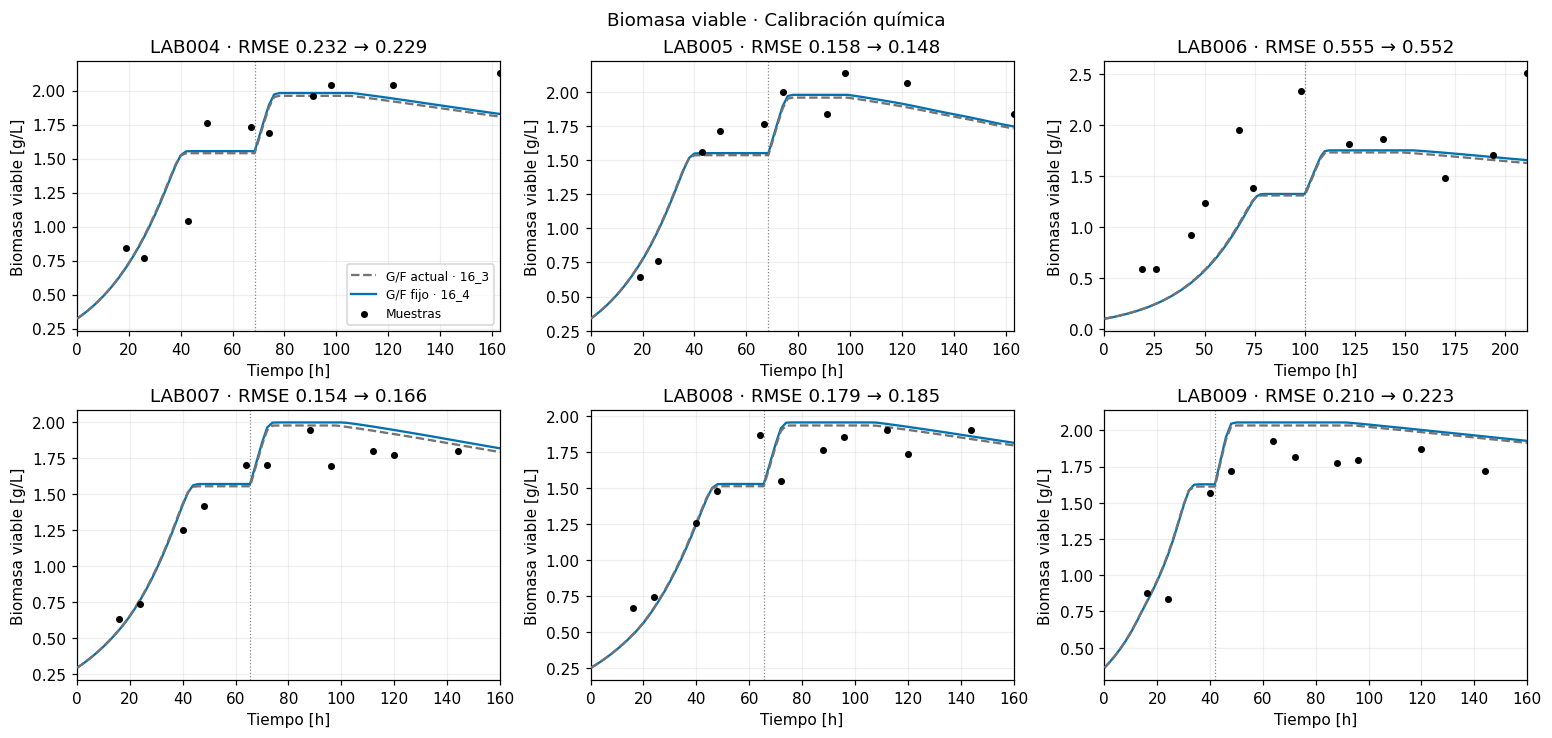

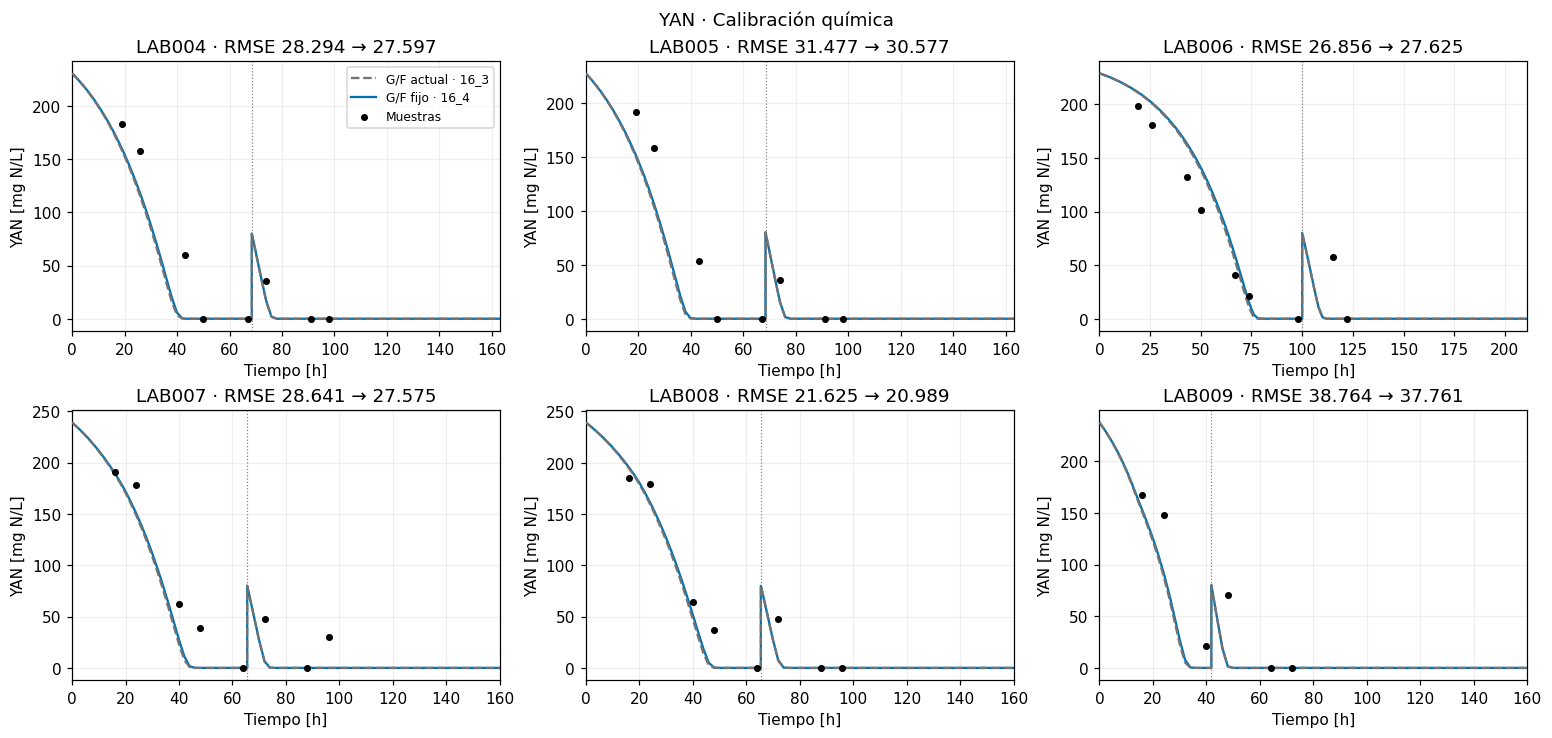

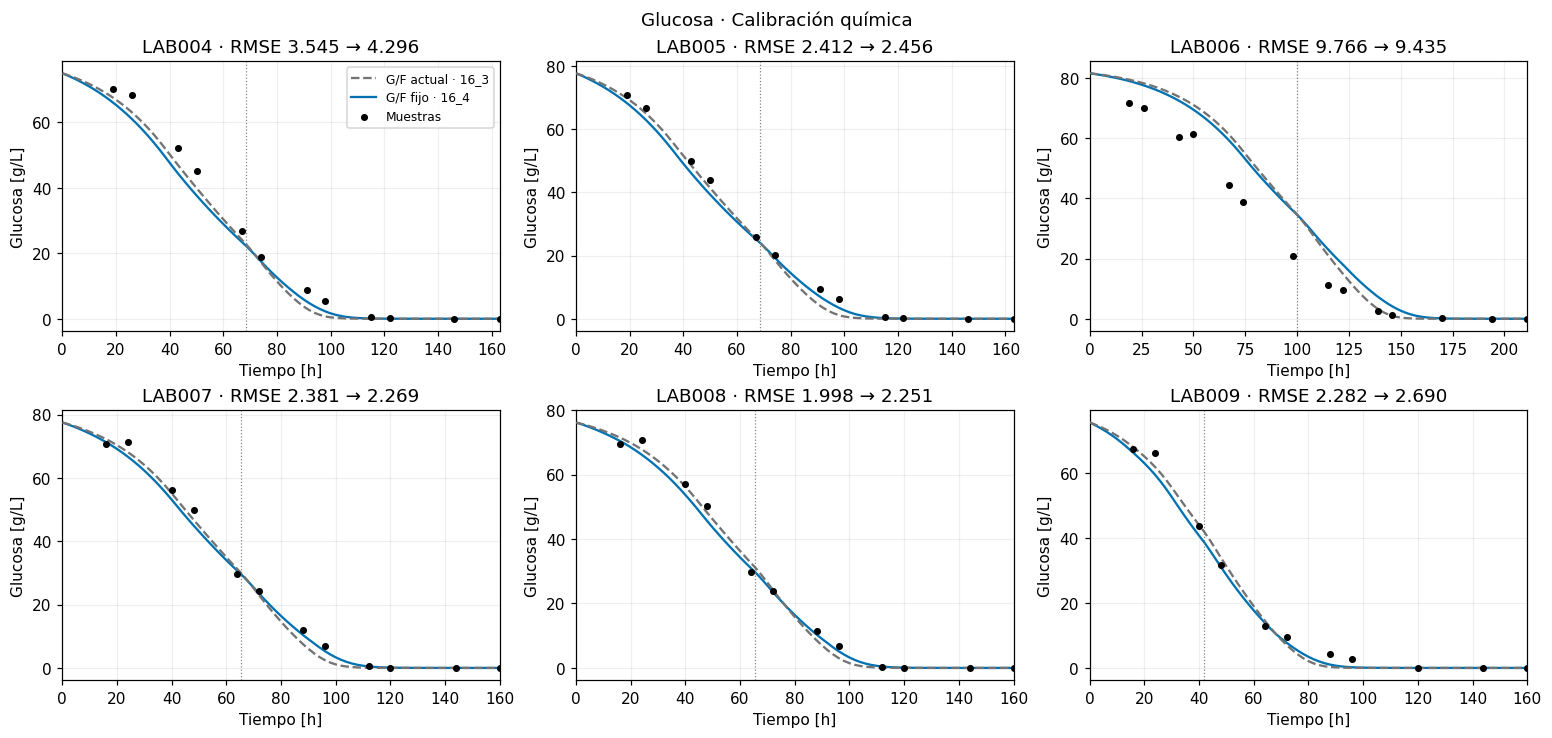

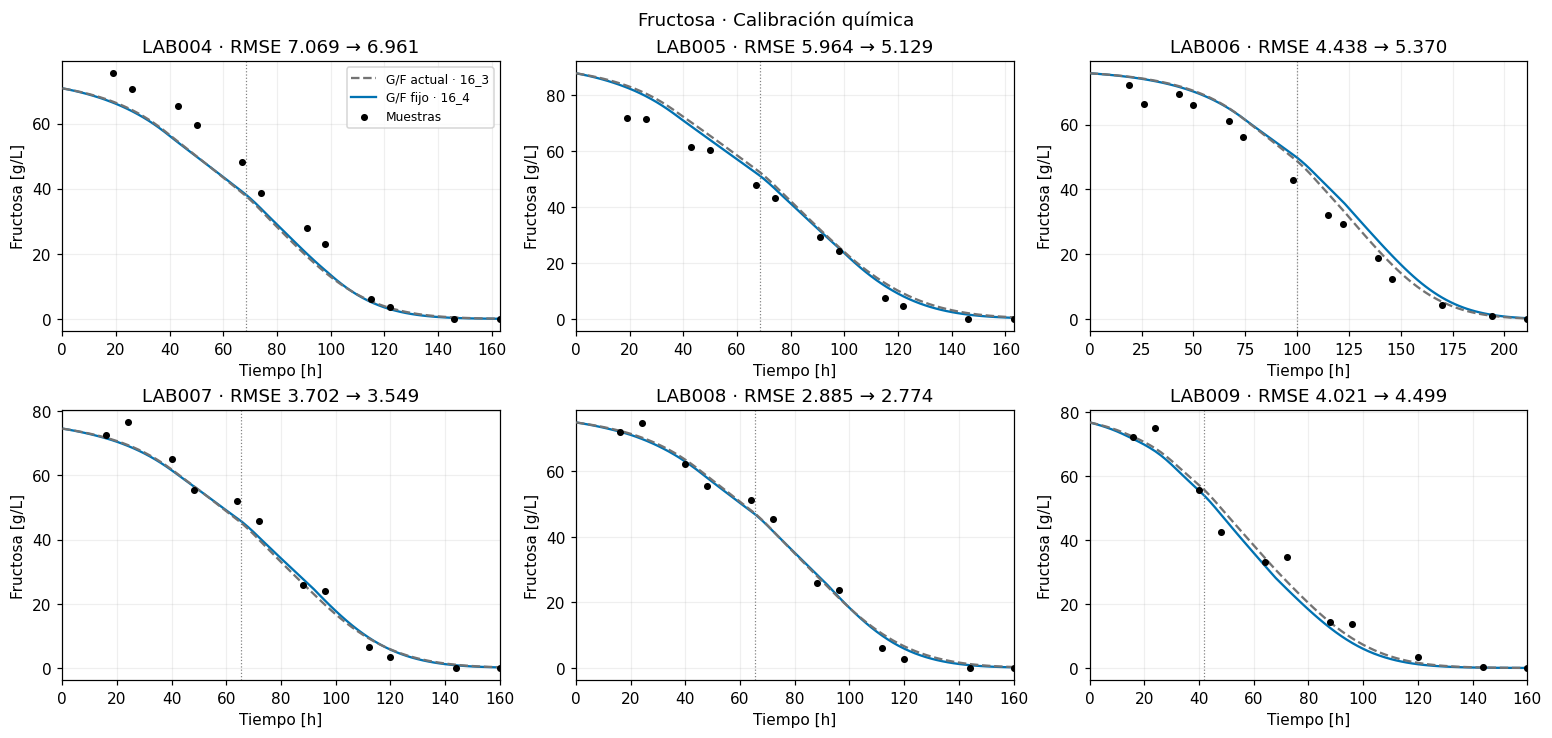

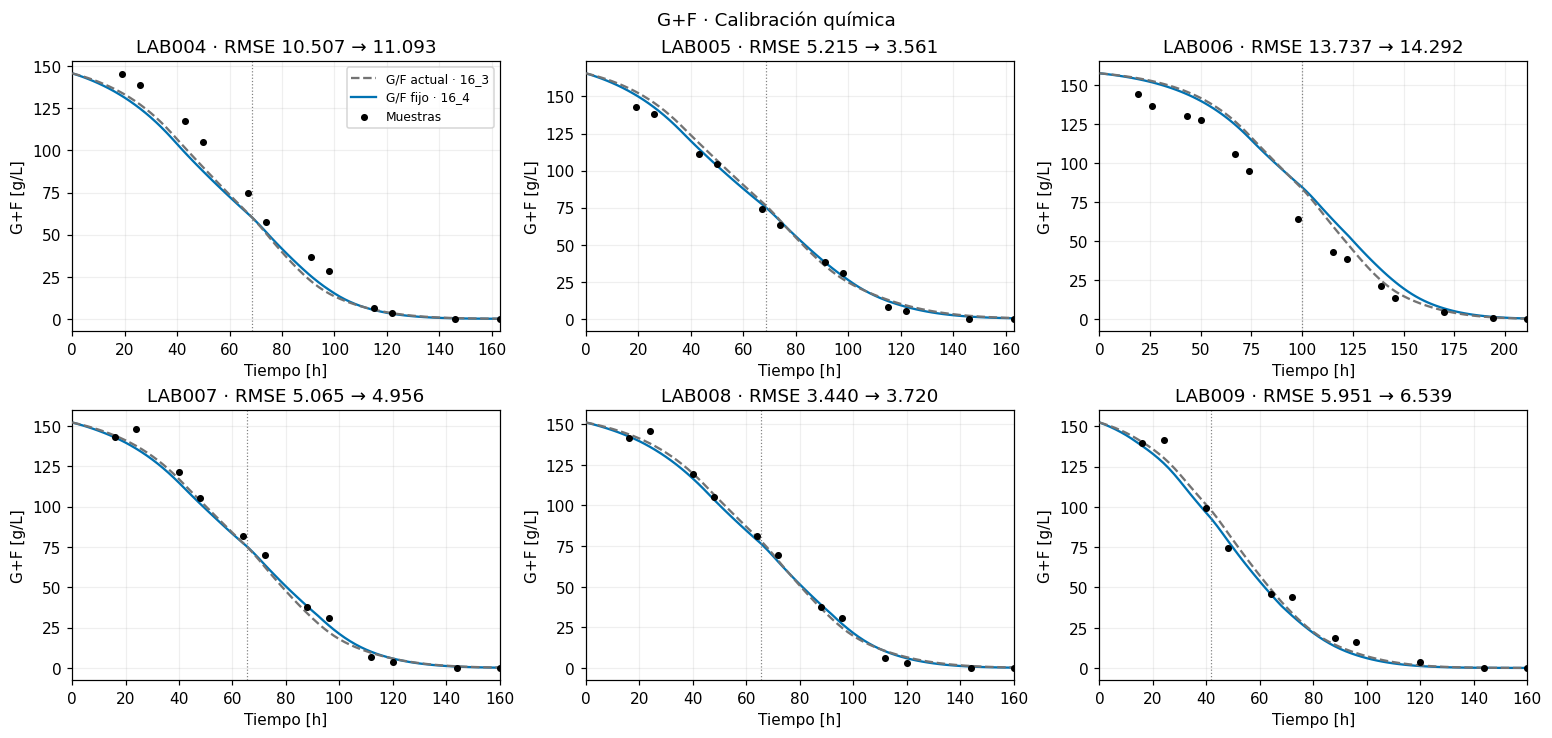

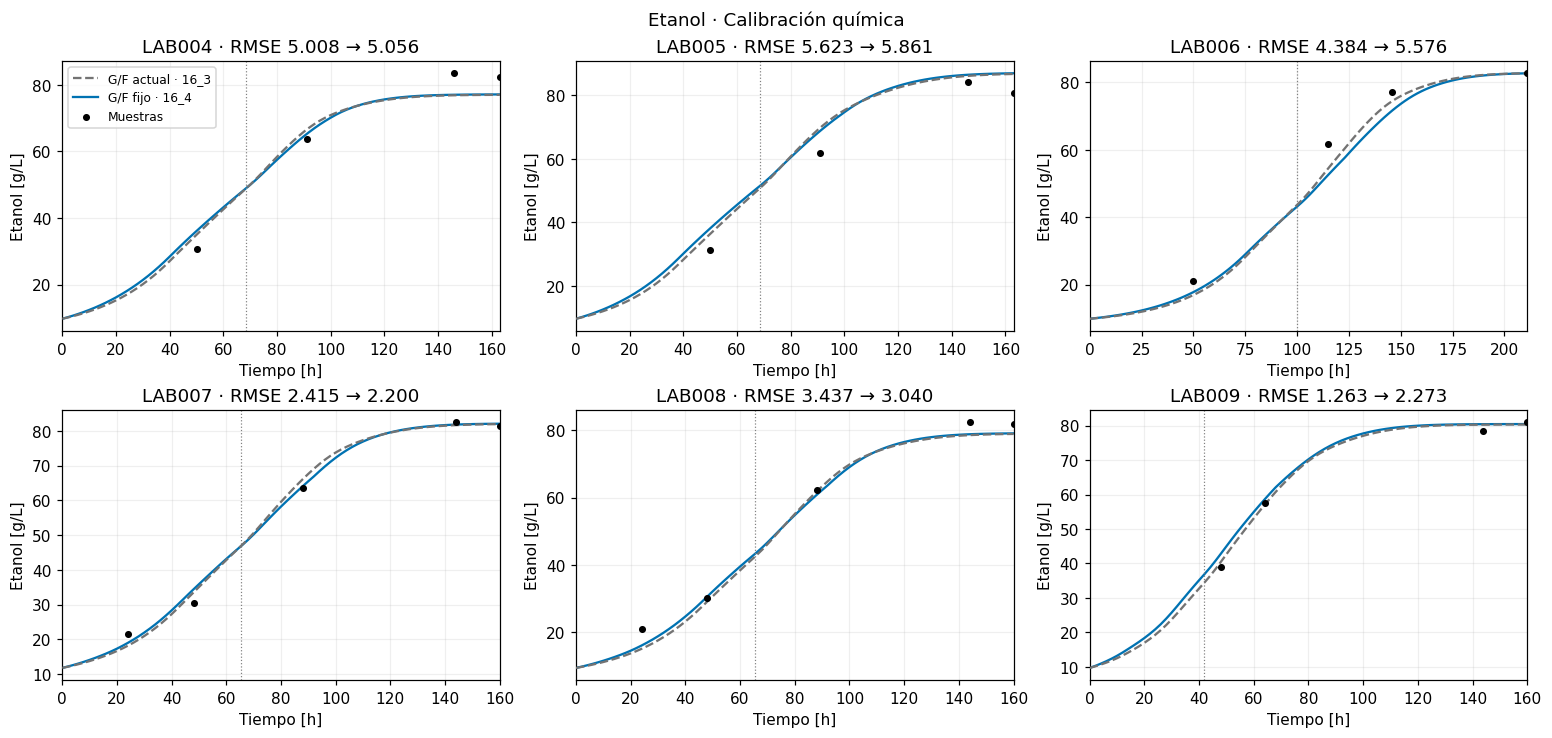

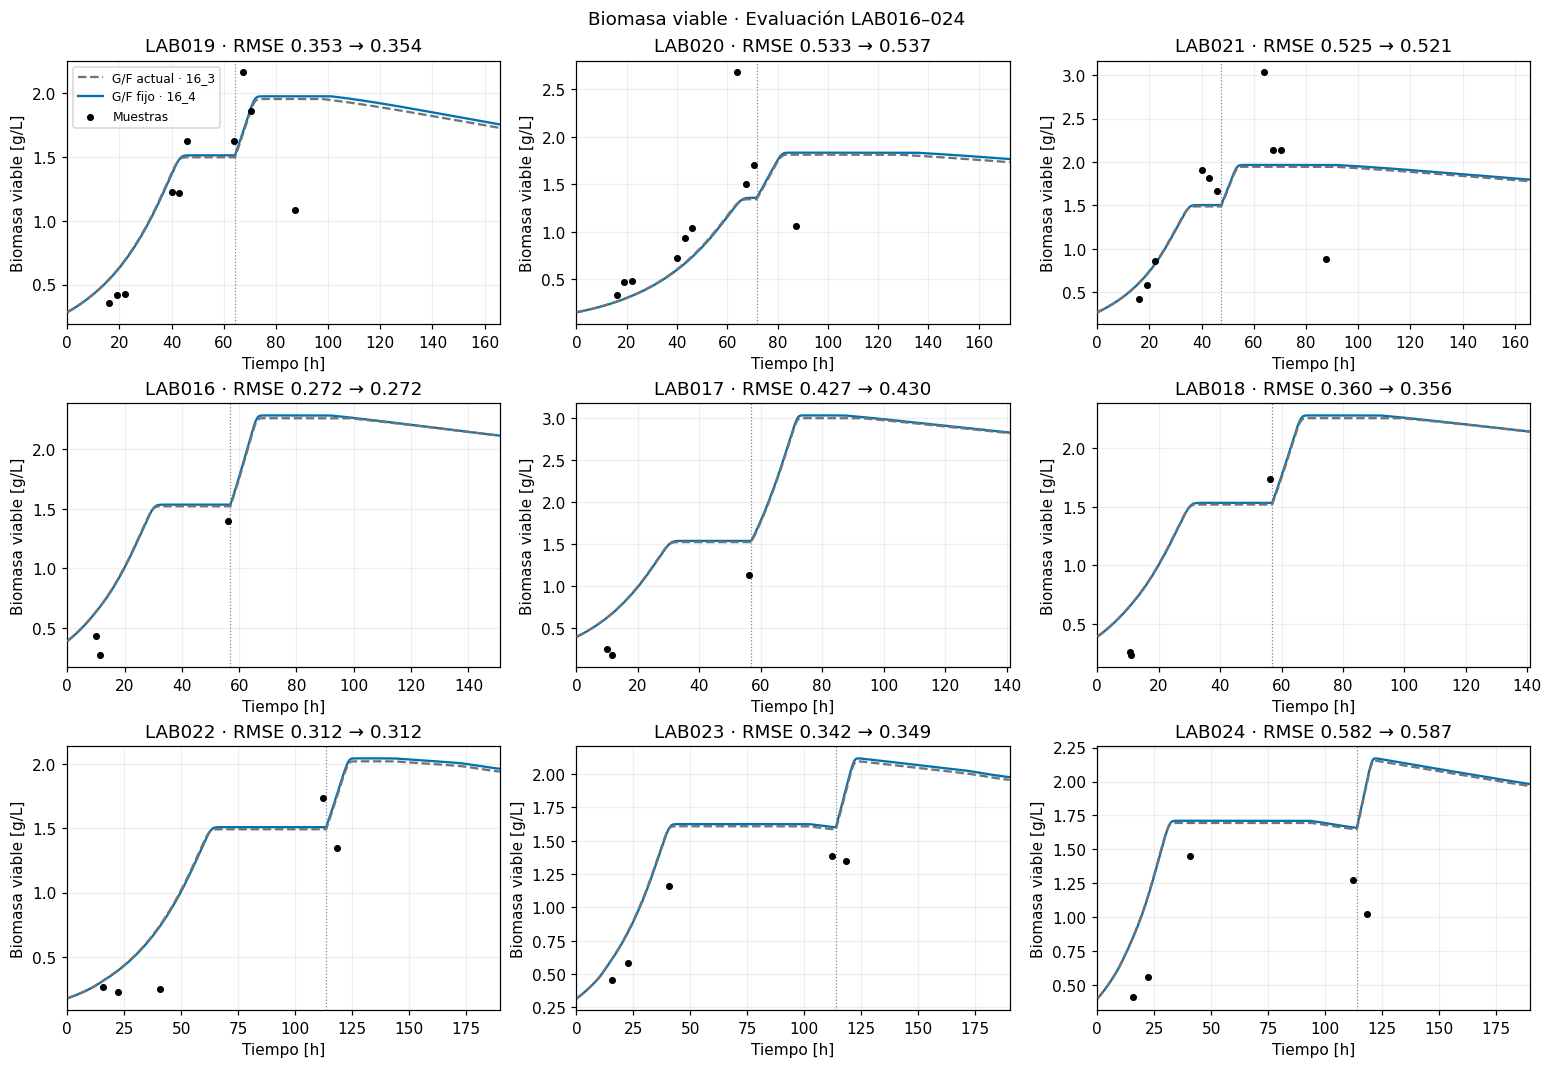

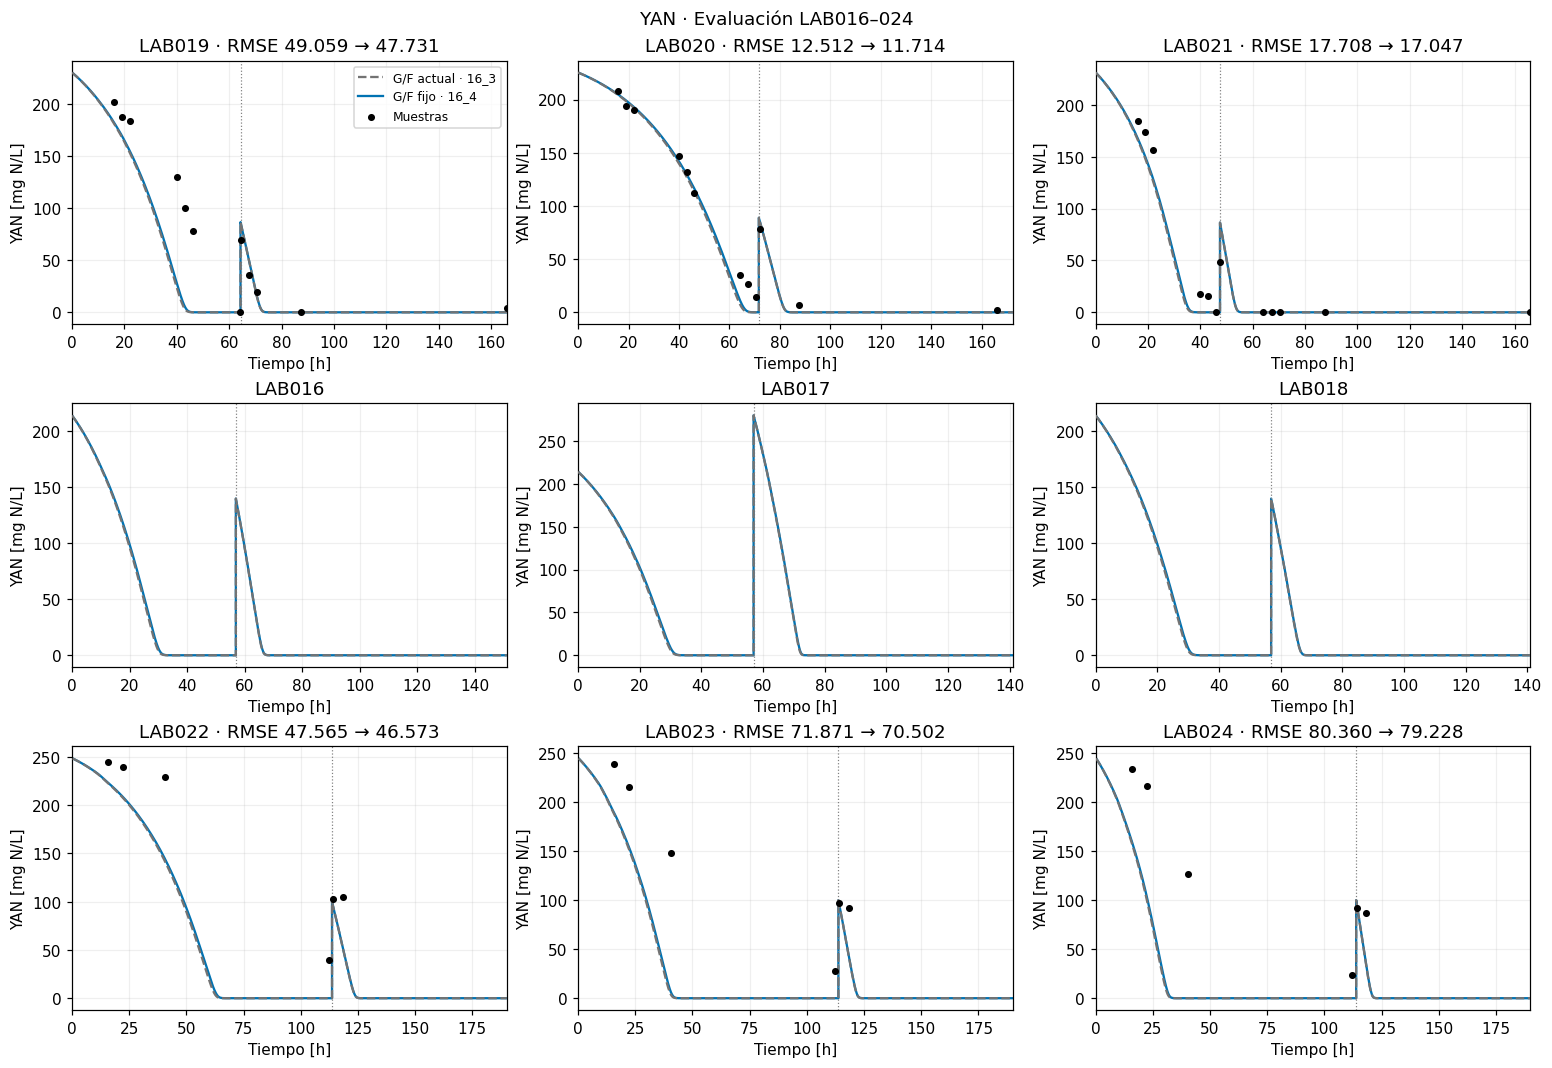

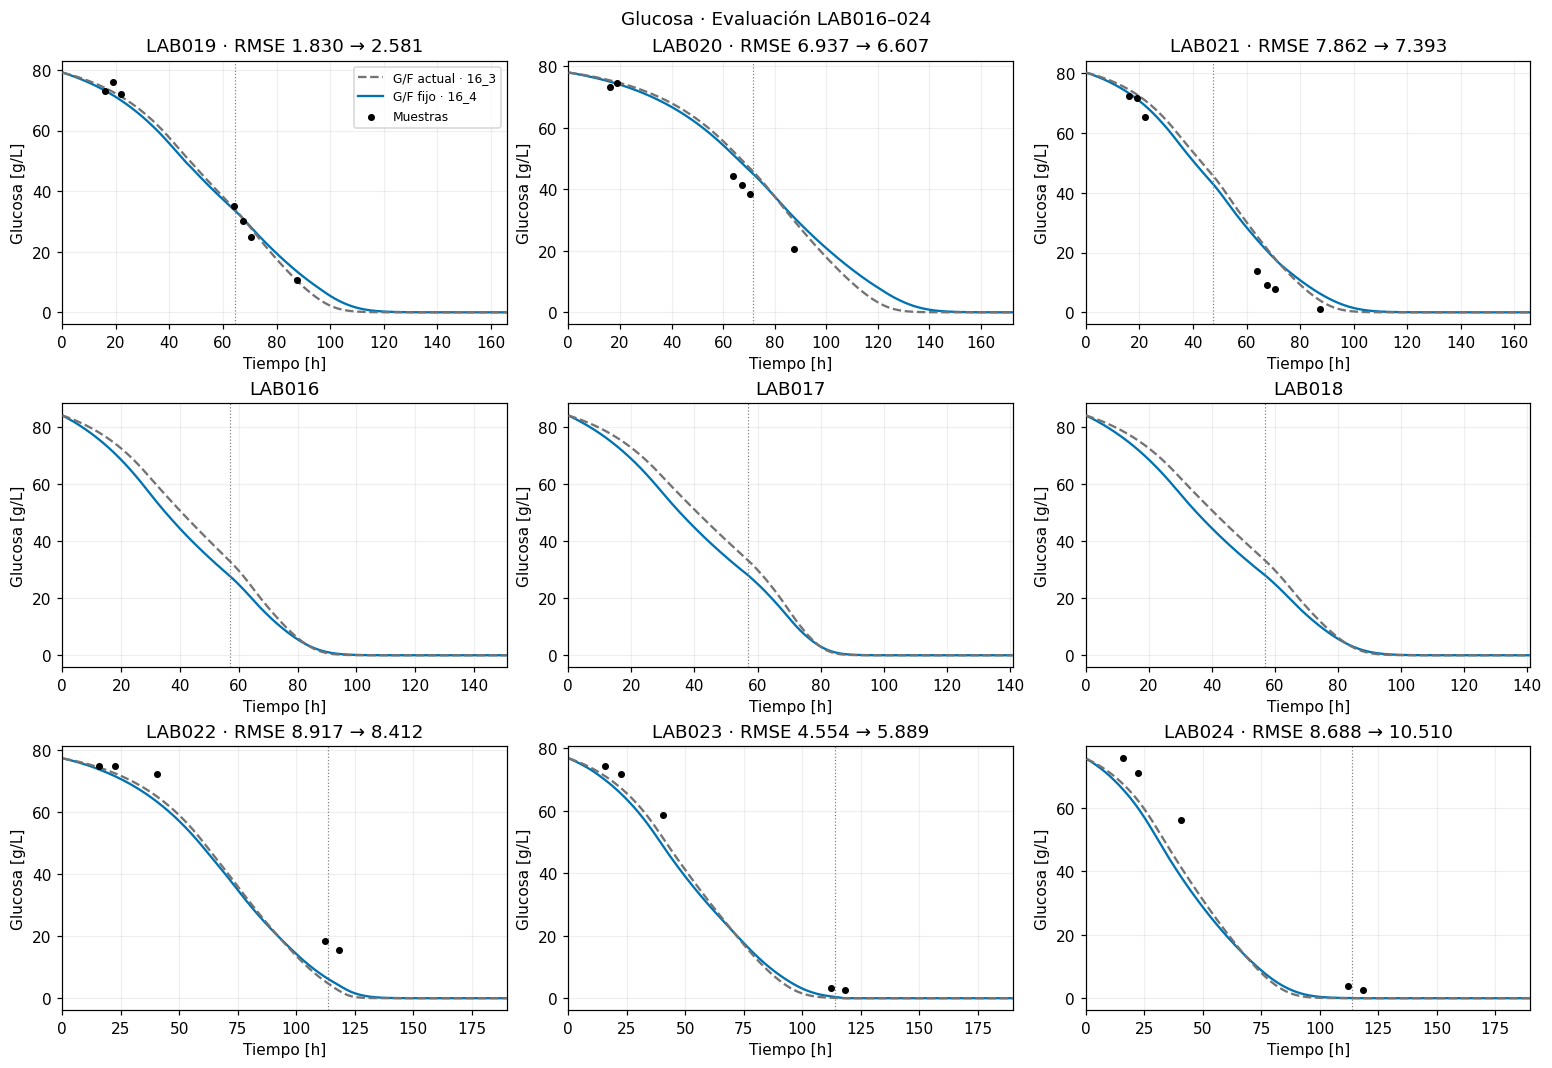

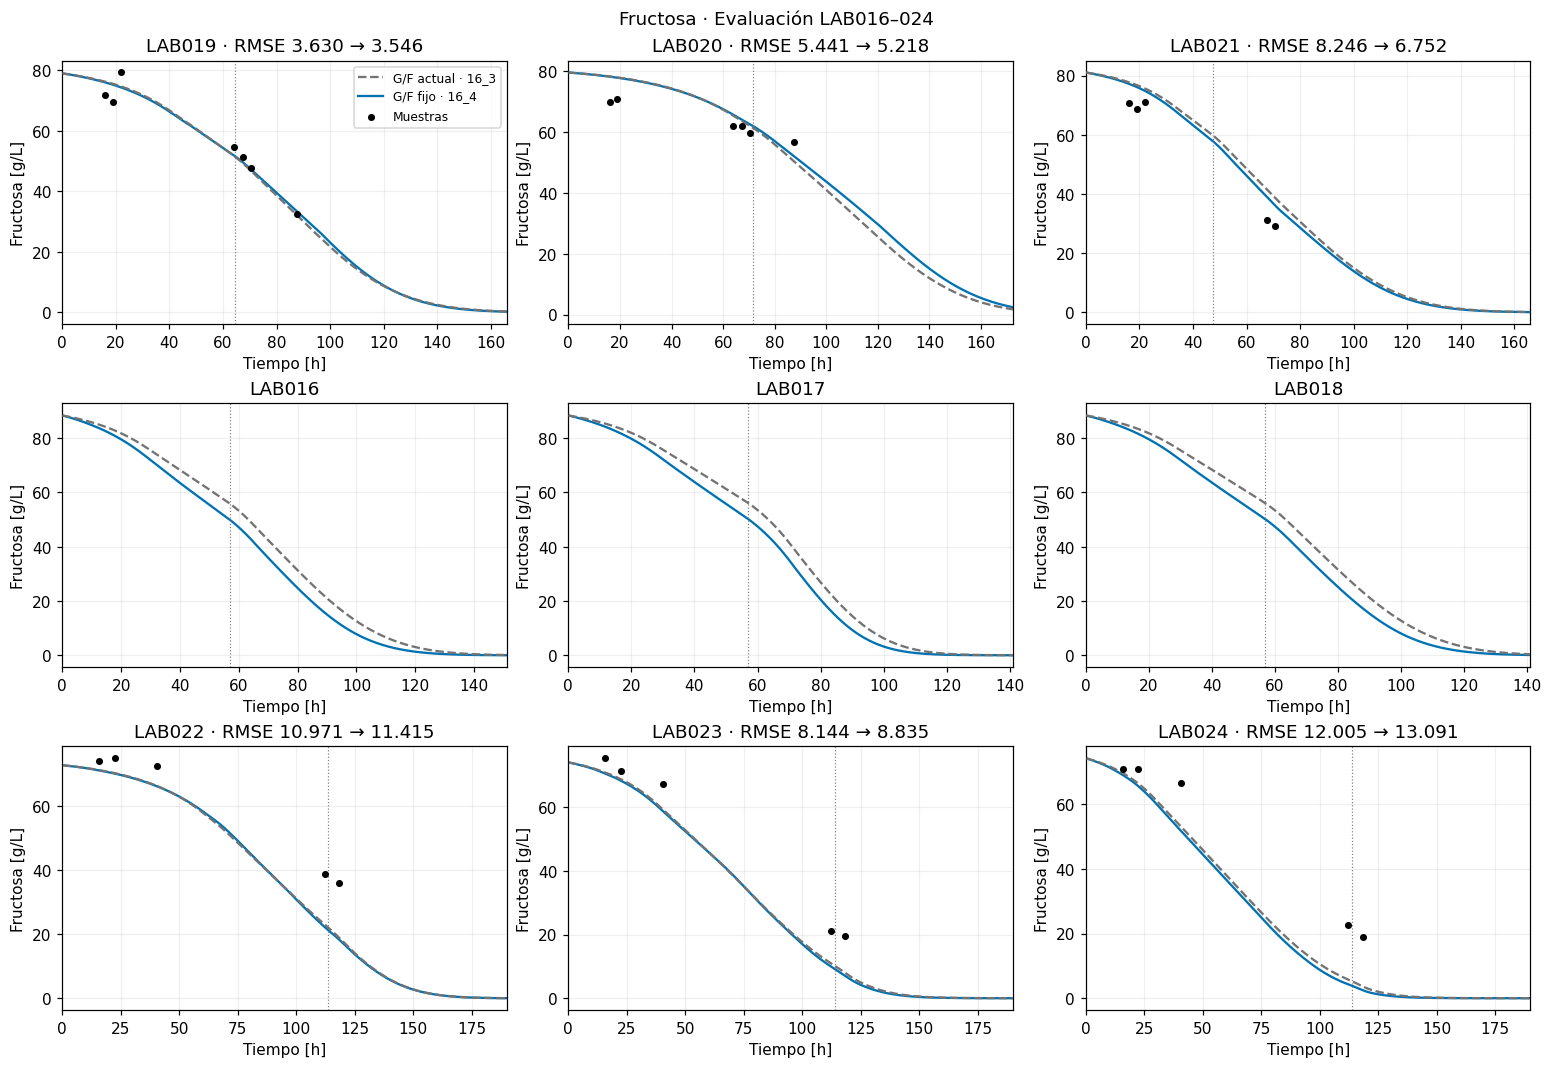

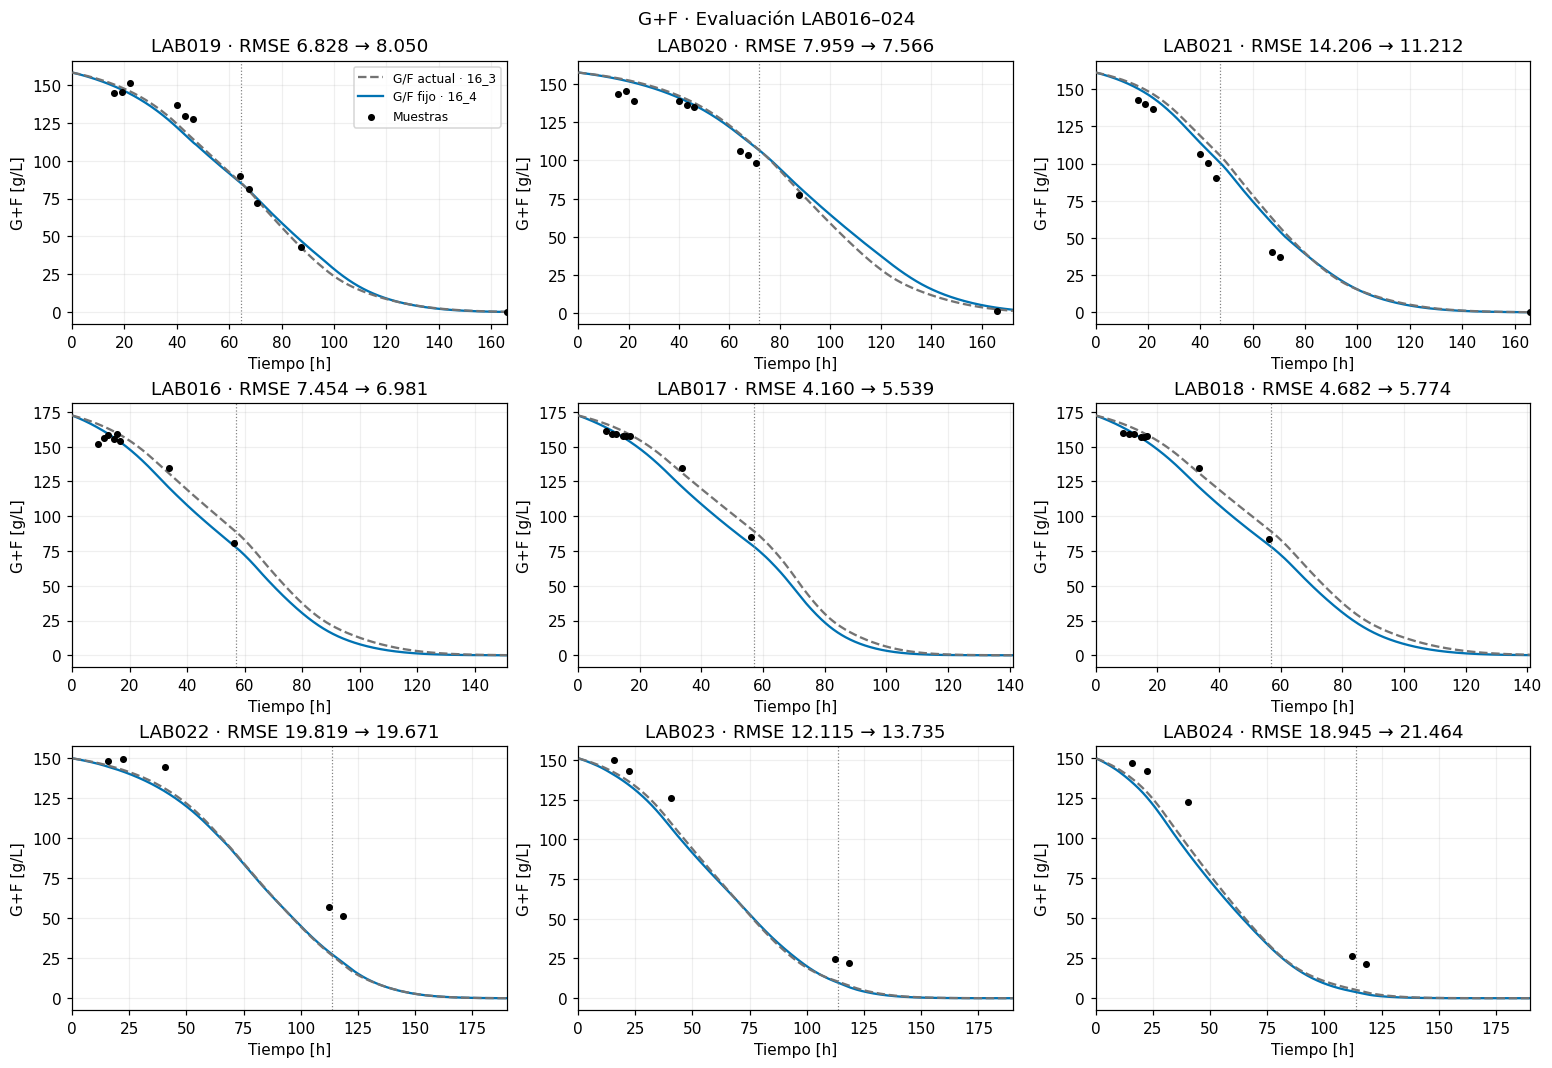

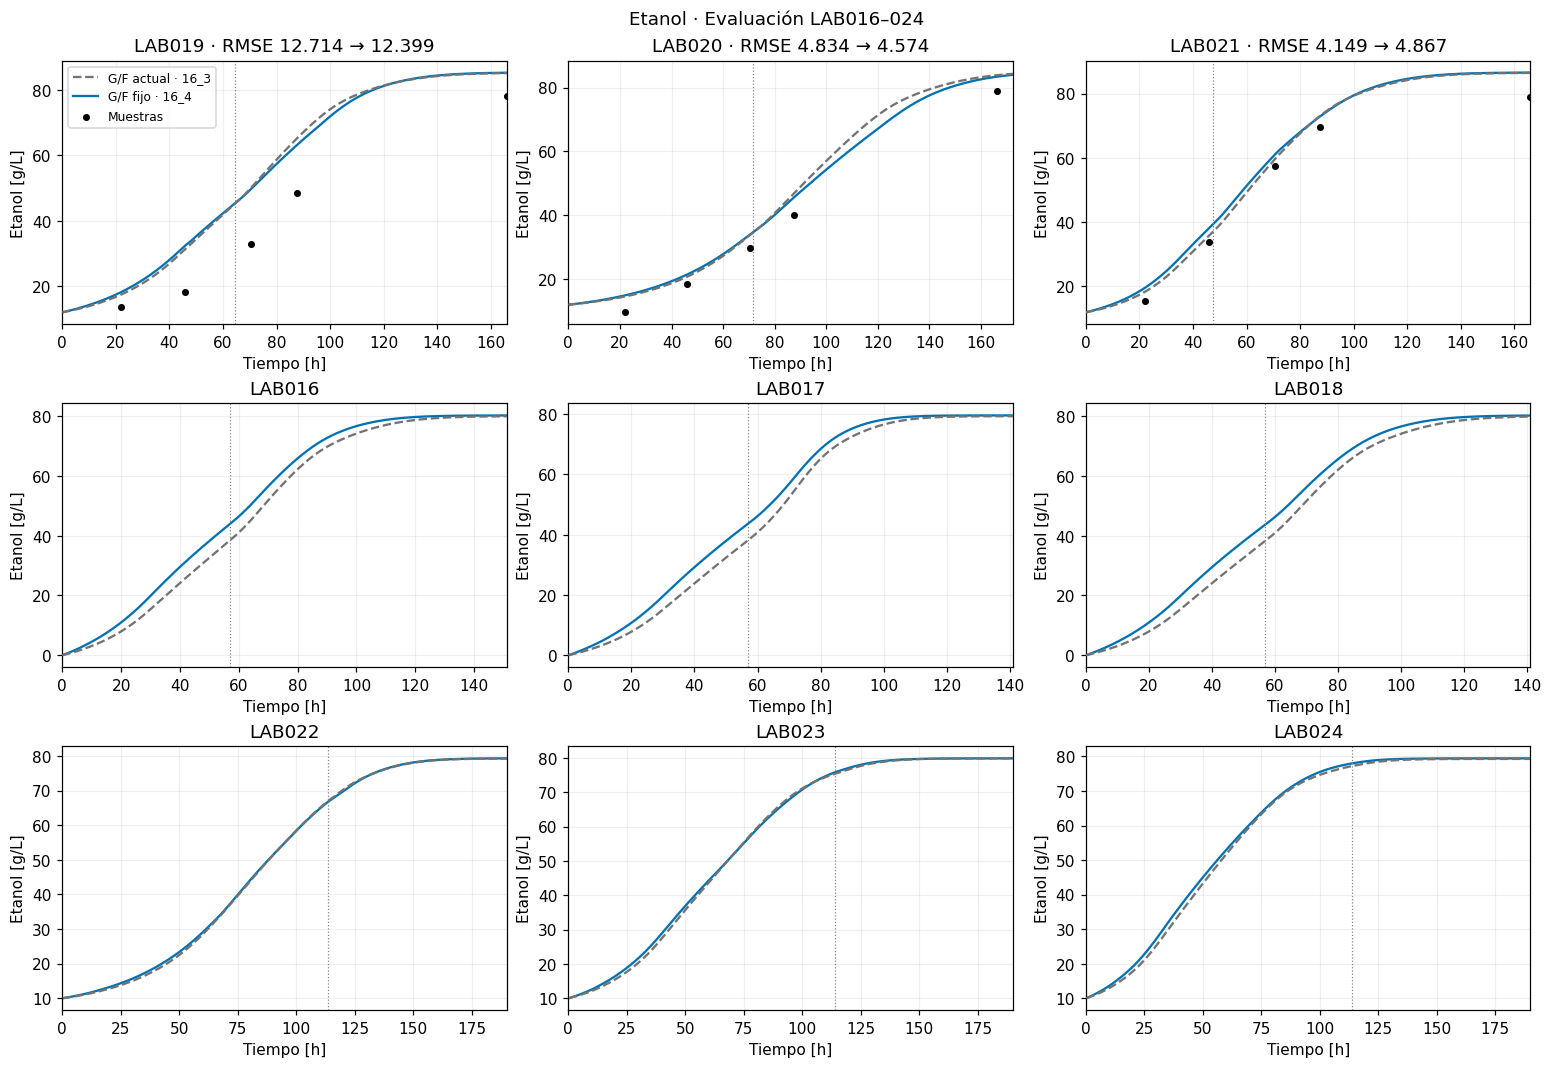

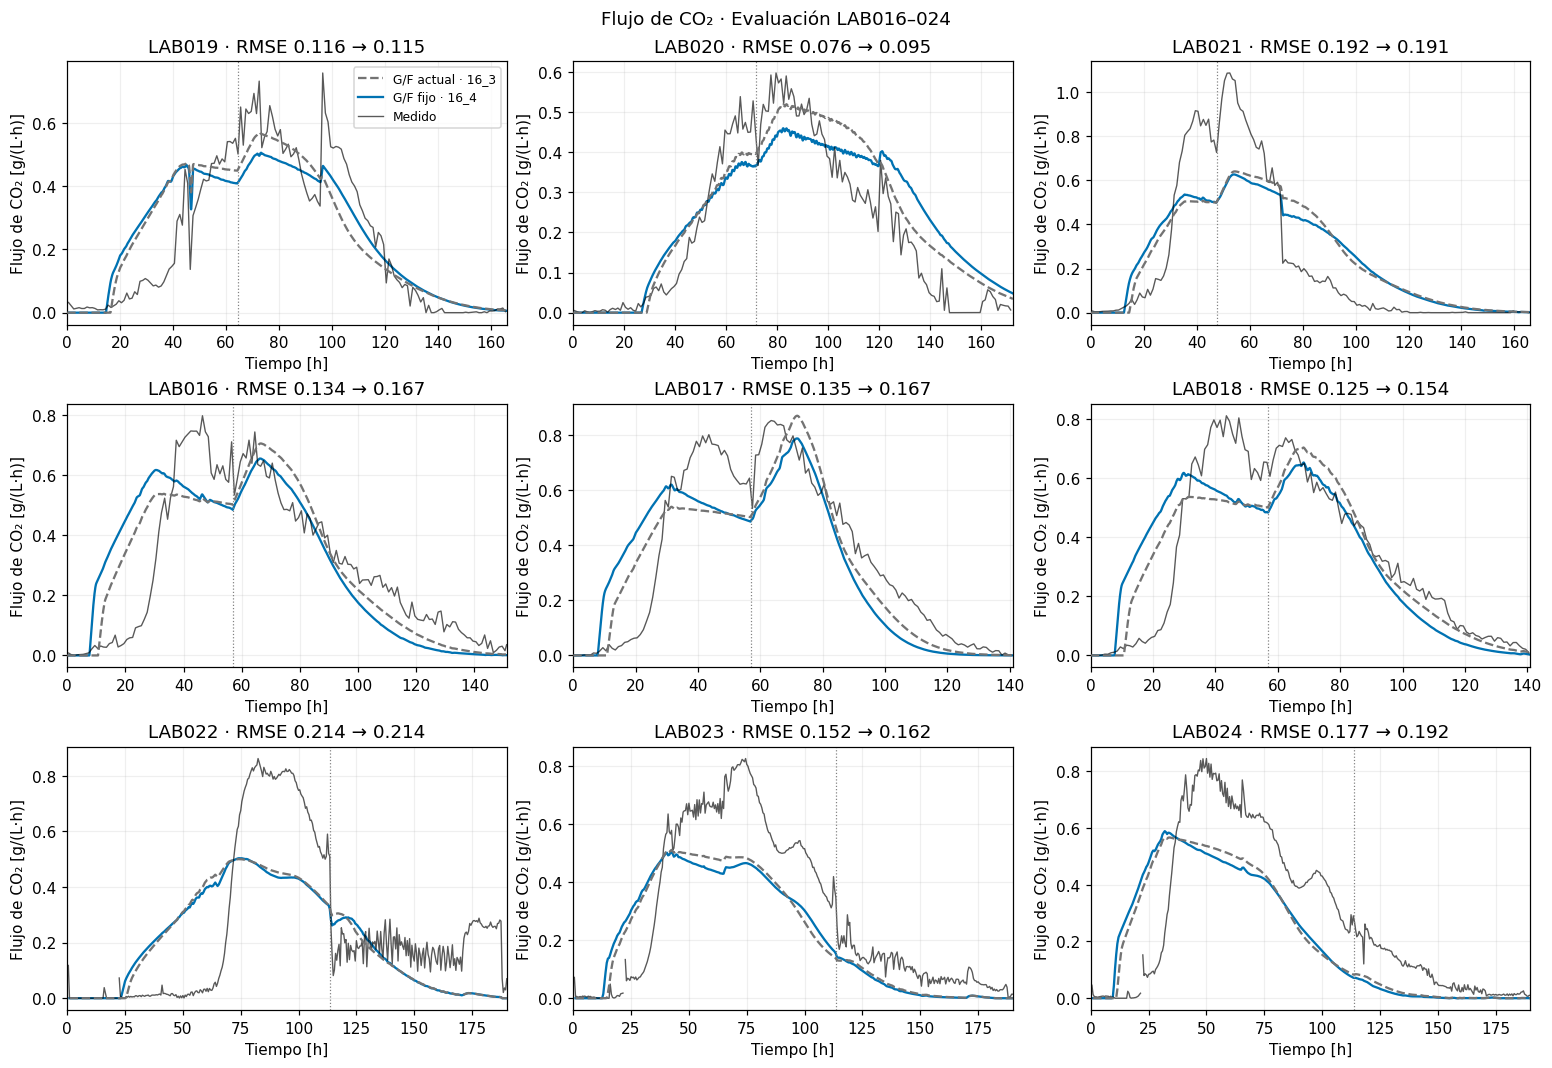

In [7]:
styles = {BASE: dict(color="#737373", linestyle="--", zorder=3),
          AVAILABLE: dict(color="#0072B2", zorder=2)}
for group, labs in (("Calibración química", tuple(training)),
                    ("Evaluación LAB016–024", (*historical, *recent))):
    for state, (title, unit, _) in VARS.items():
        if state == "CO2" and group == "Calibración química":
            continue
        fig, axes = plt.subplots(len(labs) // 3, 3, figsize=(14, 3.3 * len(labs) // 3 + .6),
                                 layout="constrained")
        for ax, lab in zip(axes.flat, labs):
            for label in LABELS:
                frame = predicted(label, lab, state, plot=True)
                ax.plot(frame.index, frame.values, label=label, **styles[label])
            obs = samples[lab, state]
            if state == "CO2":
                if lab in recent:
                    obs = setup["holdout_flow"][lab]
                ax.plot(obs.index, obs.values, color="black", alpha=.65, lw=.9, label="Medido")
            else:
                ax.scatter(obs.index, obs.values, c="black", s=13, zorder=5, label="Muestras")
            for pulse, _ in batches[lab].pulses["N"]:
                ax.axvline(pulse, c="gray", ls=":", lw=.8)
            subtitle = lab
            if (lab, state) in rmse.index:
                old, new = rmse.loc[(lab, state), list(LABELS)]
                subtitle += f" · RMSE {old:.3f} → {new:.3f}"
            horizon = v.horizons[lab] if lab in historical else batches[lab].time[-1]
            ax.set(title=subtitle, xlabel="Tiempo [h]", ylabel=f"{title} [{unit}]", xlim=(0, horizon))
            ax.grid(alpha=.2)
        axes.flat[0].legend(fontsize=8)
        fig.suptitle(f"{title} · {group}")
        plt.show()

## Temperaturas de calibración

Se muestran las mediciones y el perfil de temperatura utilizado por ambos modelos en LAB004–009.

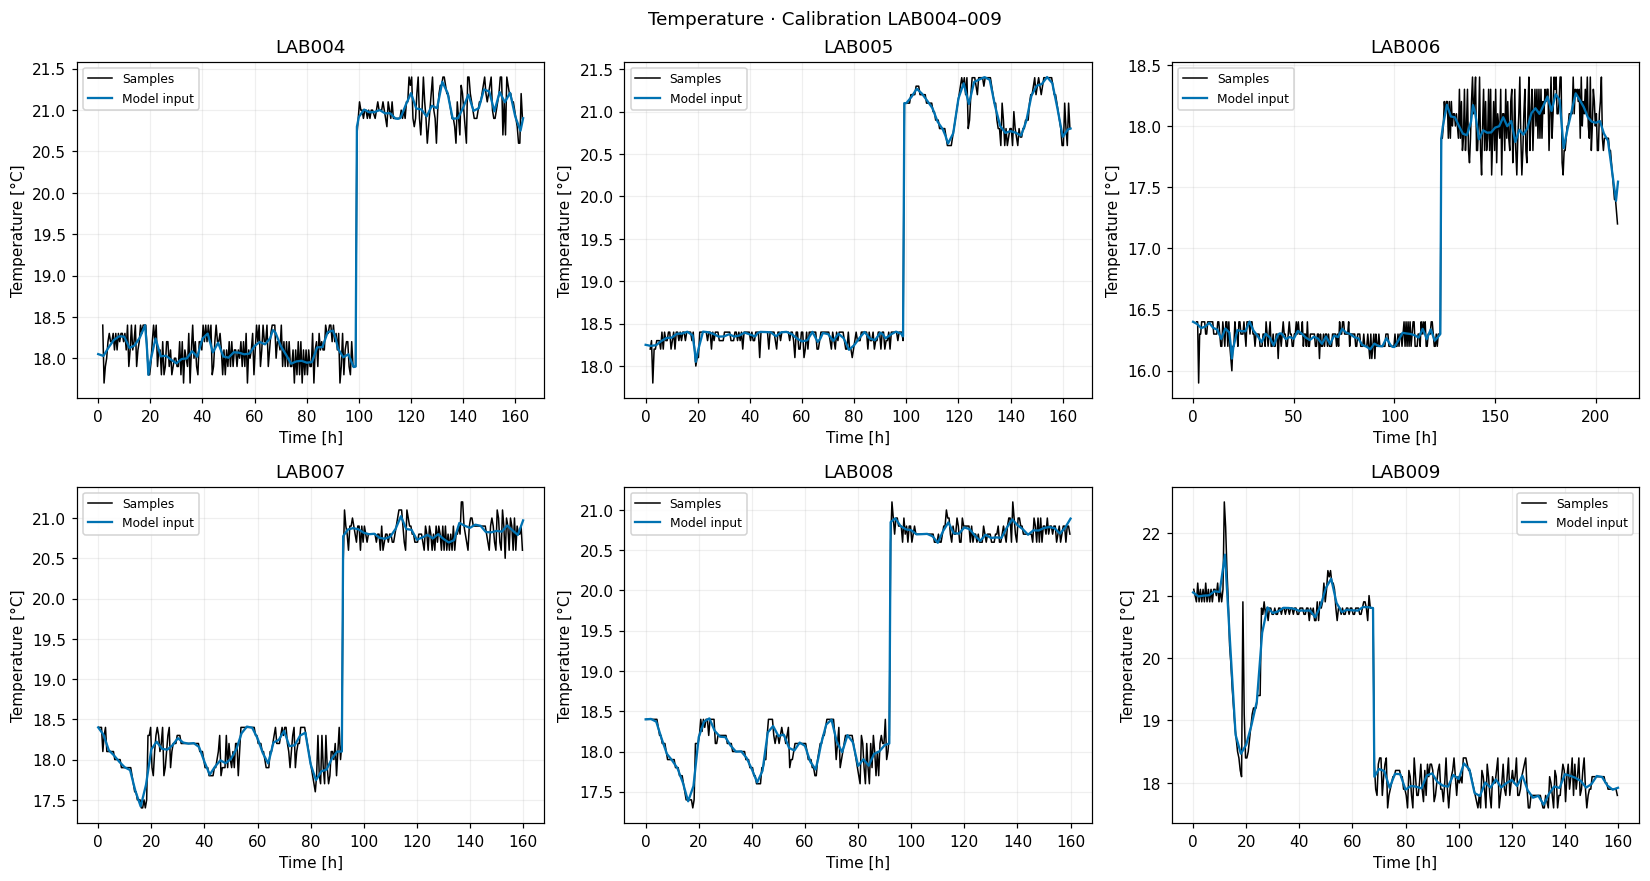

In [8]:
profiles = setup["profiles"]
treated = setup["treated"]
# Perfiles térmicos medidos de los entrenamientos y perfil filtrado usado por las simulaciones.
fig,axs=plt.subplots(2,3,figsize=(15,8))
for ax,b in zip(axs.flat,treated):
 p=profiles[b.batch].loc[lambda p: p.t_h.between(b.time[0], b.time[-1])]
 ax.plot(p.t_h,p['T'],c='black',lw=1,label='Samples')
 ax.plot(b.time,b.temperature_c,c='#0072B2',lw=1.5,label='Model input')
 assert len(p)==len(p.dropna(subset=['t_h','T'])) and np.isfinite(b.temperature_c).all()
 assert set(ax.get_legend_handles_labels()[1])=={'Samples','Model input'}
 ax.set(title=b.batch,xlabel='Time [h]',ylabel='Temperature [°C]');ax.grid(alpha=.2)
fig.suptitle('Temperature · Calibration LAB004–009',y=.99);fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9)
for ax in axs.flat:
 hs,ls=ax.get_legend_handles_labels();unique=dict(zip(ls,hs))
 ax.legend(unique.values(),unique.keys(),loc='best',fontsize=8,framealpha=.85)
assert not fig.legends;plt.show()

## Comprobaciones finales

Se comprueban las constantes fijadas, los parámetros que se conservaron, los pulsos, las condiciones iniciales y la igualdad del soporte de comparación. La convergencia del optimizador corresponde a un ajuste local.

In [9]:
assert len(trajectories[BASE]) == len(trajectories[AVAILABLE]) == 15
assert "Kig0" not in FREE_PARAMS and "Kie0" not in FREE_PARAMS
assert len(FREE_PARAMS) == 6
for name in theta_fixed:
    if name not in FREE_PARAMS and name != "Kie0":
        assert theta_fixed[name] == theta[name]
assert theta_fixed["Kie0"] == 40.
assert all(np.isfinite(value) for value in weighted.values())
assert len(rmse) and rmse["n"].gt(0).all()
print("Ajuste actual reproducido; seis parámetros recalibrados; inhibición fijada por lote.")
print("MSE ponderado", weighted)

Ajuste actual reproducido; seis parámetros recalibrados; inhibición fijada por lote.
MSE ponderado {'G/F actual · 16_3': 4.715502281177189, 'G/F fijo · 16_4': 4.774649261476047}


## Lectura de los resultados

Resultados de la ejecución guardada con \(K_{IE0}=40\,\mathrm{g/L}\) y \(K_{IG0}=(G_0+F_0)/4\) fijo dentro de cada lote. Ambos arranques convergen y el ajuste reproduce el objetivo del modelo actual.

| Comparación | G/F actual · 16_3 | G/F fijo · 16_4 | Cambio |
|---|---:|---:|---:|
| Promedio de cuadrados de residuos ponderados · LAB004–009 | 4,715502 | 4,774649 | +1,25 % |
| Raíz del error cuadrático medio de biomasa · LAB016–024 [g/L] | 0,4466 | 0,4479 | +0,28 % |
| Raíz del error cuadrático medio de nitrógeno · LAB016–024 [mg N/L] | 46,7135 | 45,7393 | −2,09 % |
| Raíz del error cuadrático medio de azúcar total · LAB016–024 [g/L] | 10,8736 | 11,0566 | +1,68 % |
| Raíz del error cuadrático medio de dióxido de carbono · LAB016–024 [g/(L·h)] | 0,1625 | 0,1738 | +6,95 % |

Los errores de evaluación se calculan agrupando las mismas observaciones disponibles por variable. El error de gas conserva los coeficientes heredados y las ventanas de comparación del 16_3. LAB019–021 participaron en la calibración previa de esos coeficientes.

La inhibición más intensa se compensa en el ajuste con aumentos de las tasas máximas de producción de etanol. \(\beta_{G0}\) pasa de 0,428291 a 0,655372 (+53,02 %) y \(\beta_{F0}\) de 0,593521 a 1,285102 (+116,52 %), en g de etanol por g de biomasa y hora. El rendimiento \(Y_{E/F}=0,511391\) queda prácticamente en su cota superior de 0,5114 g/g. Estos resultados corresponden a la interpretación de \(S/4\) mediante el azúcar inicial de cada lote y a las cotas del ensayo.